In [ ]:
!pip install gymnasium

## **'FrozenLake-v1'with learning in only when episode end**

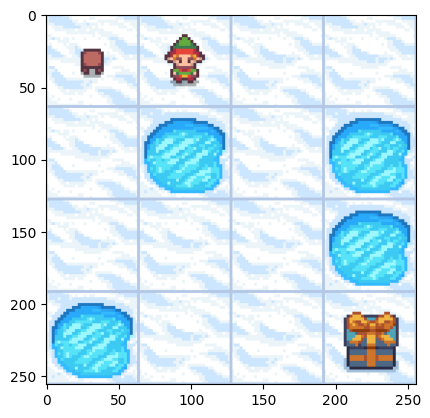

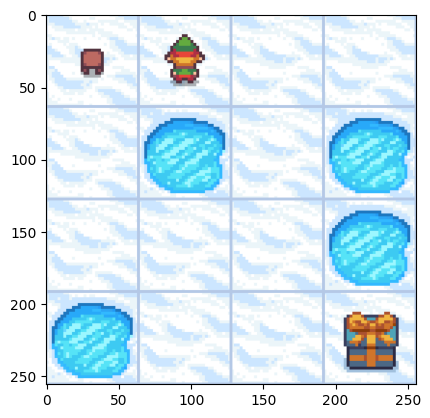

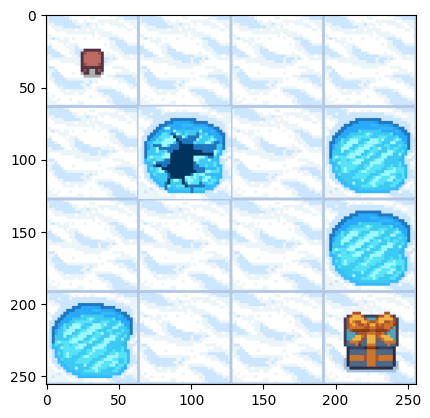

[(0, np.int64(1), 0), (1, np.int64(3), 0), (1, np.int64(2), 0)]


In [ ]:

import gymnasium as gym
import matplotlib.pyplot as plt

# Create environment (with visual rendering)
env = gym.make("FrozenLake-v1", render_mode="rgb_array") #render_mode→in which format to show environment

# Render function
def render():
    frame = env.render()       # Get image (RGB array)
    plt.imshow(frame)          # Show image
    plt.show()

def generate_episode():
    episode = []
    '''this list will save tuples in this form (state, action, reward)'''
    # Reset the environment
    state, info = env.reset() #Starts the environment from the beginning
    terminated = False #if terminated =True game ends
    while not terminated:
      # Select a random action
      action = env.action_space.sample() #Picks a random move according to game environment
      next_state, reward, terminated, truncated, info = env.step(action)
      '''after action is taken using env.step(action),
       then these  next_state, reward, terminated values are updated
       next_state → new position after action
       ward → number received (good or bad)
       terminated → game ended normally?(returns true or false)
       truncated → stopped due to time limit(returns true or false)
       info → extra info (ignored)'''
      render()
      # Update episode data
      episode.append((state,action,reward))
      #(state,action,reward) is added in episode list
      state = next_state #put next_state value in state
    return episode
print(generate_episode())

**"FrozenLake-v1" with learning in each step (SARSA)**

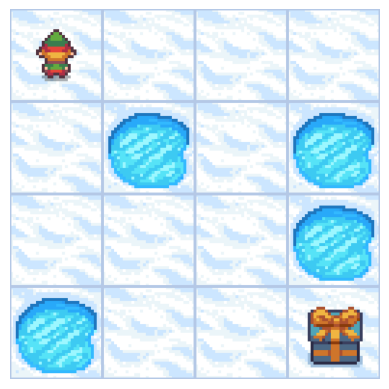

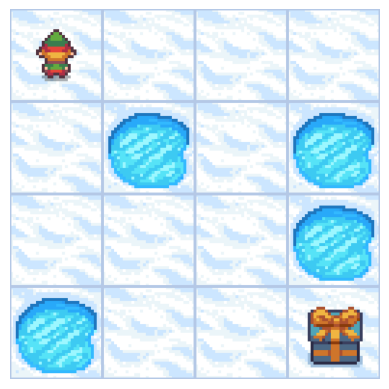

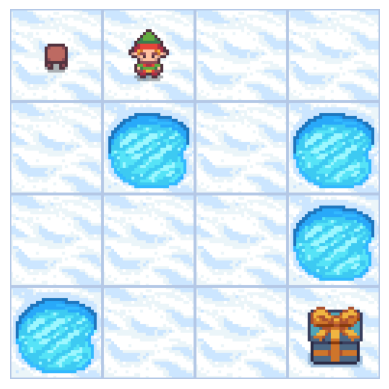

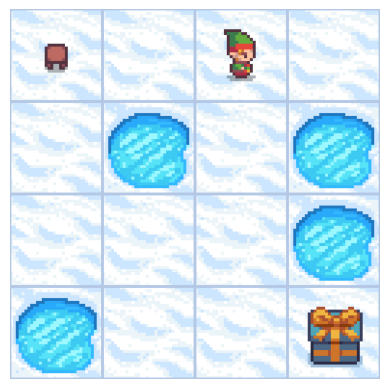

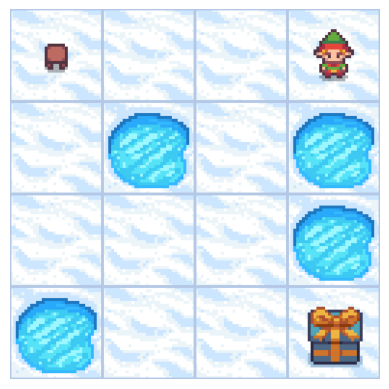

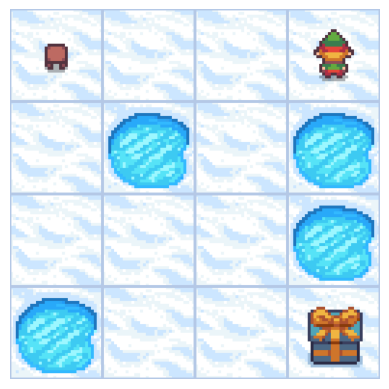

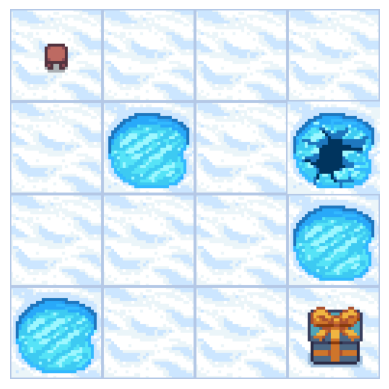

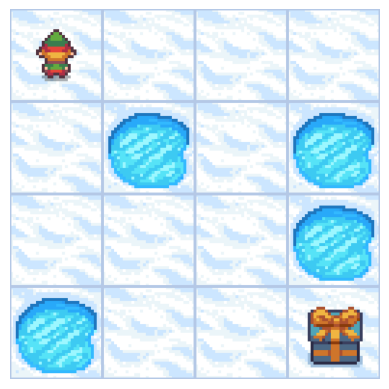

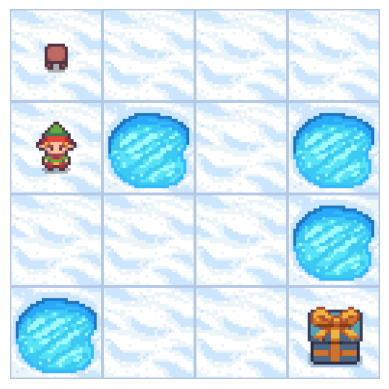

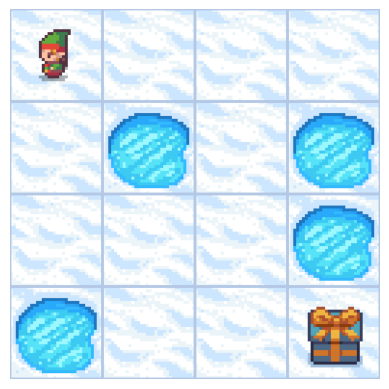

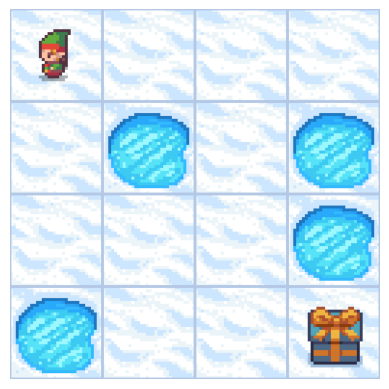

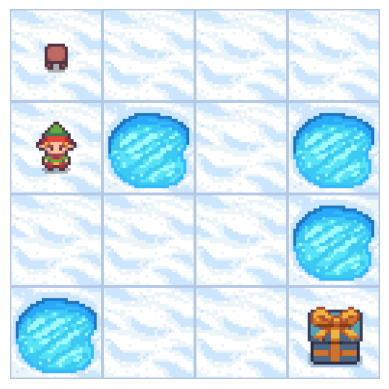

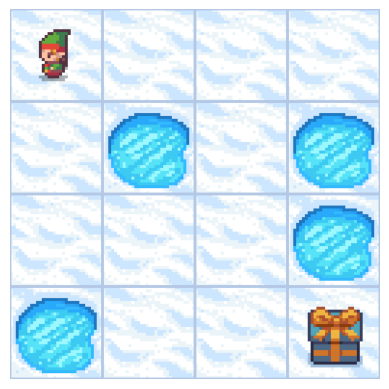

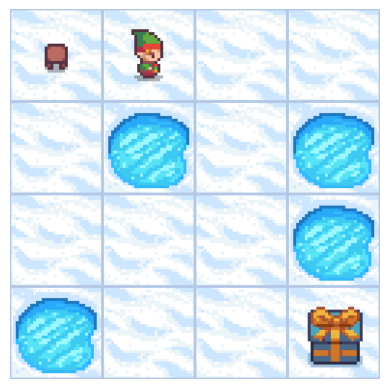

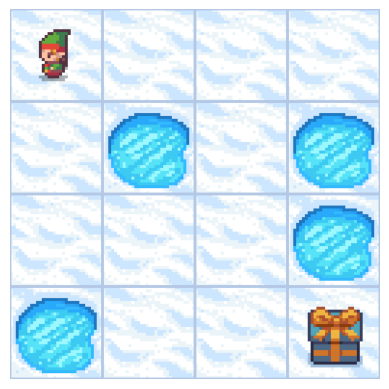

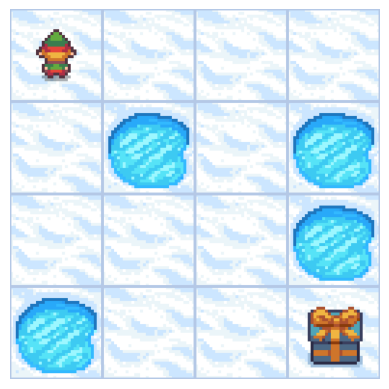

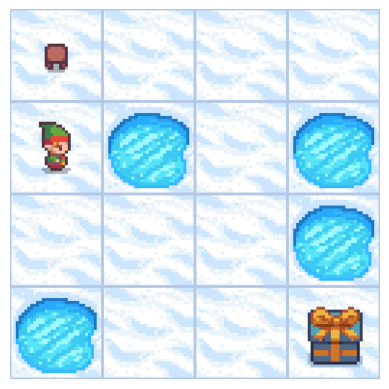

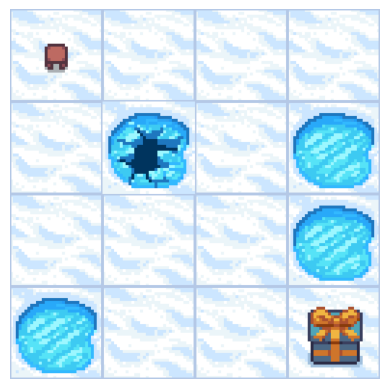

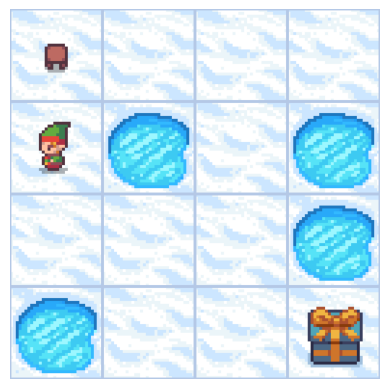

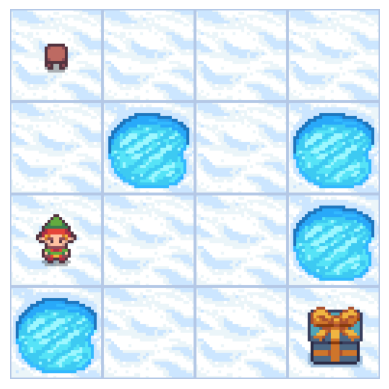

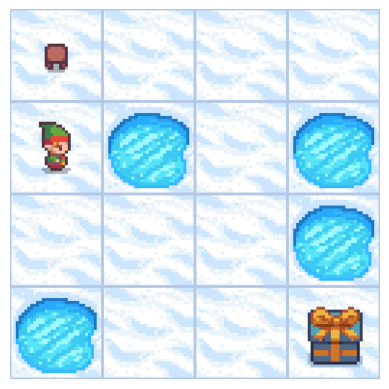

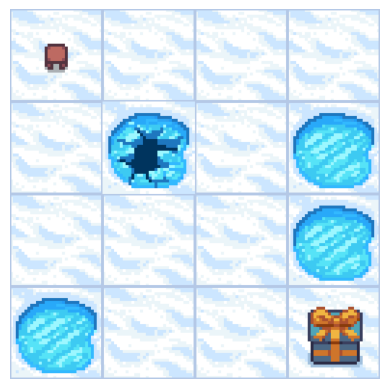

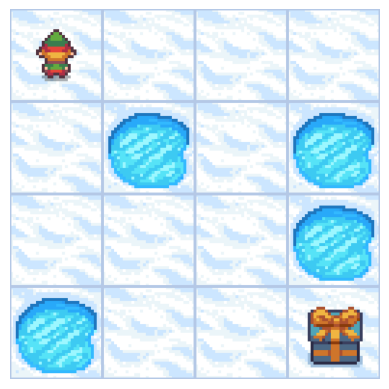

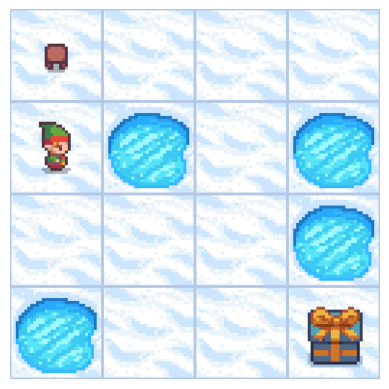

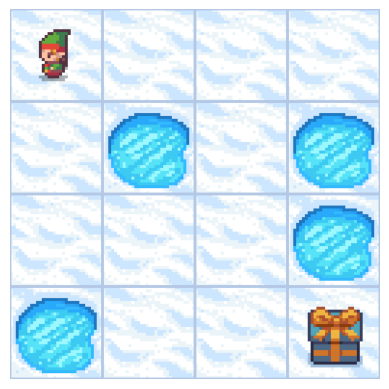

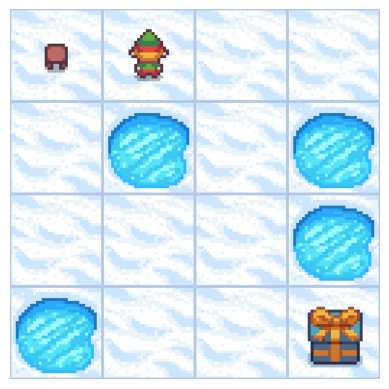

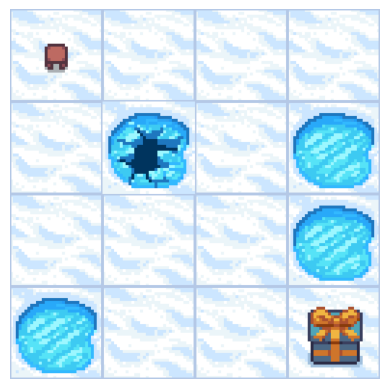

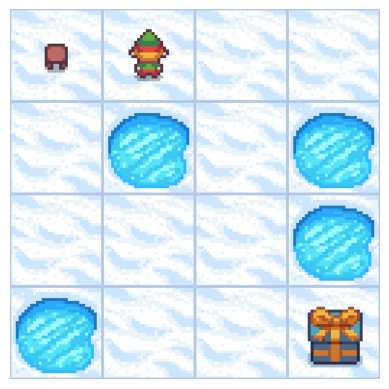

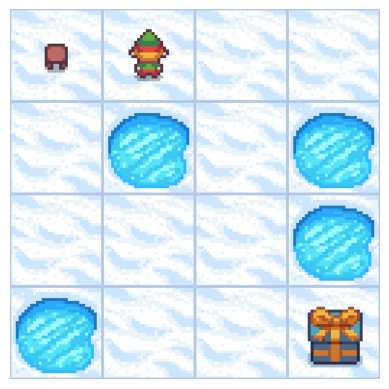

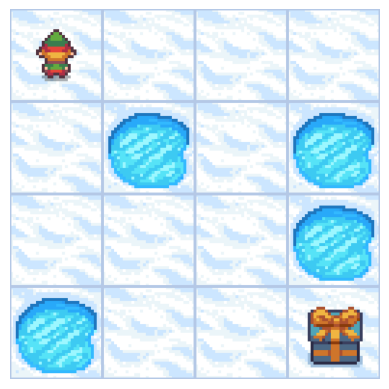

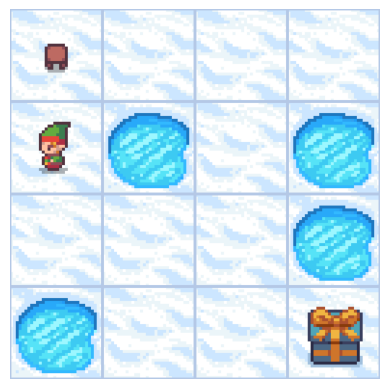

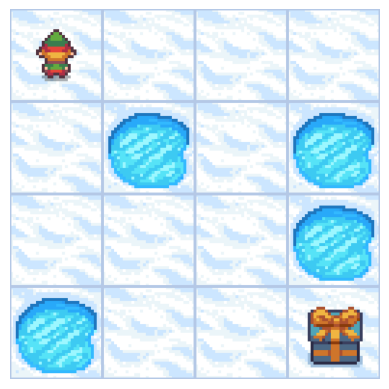

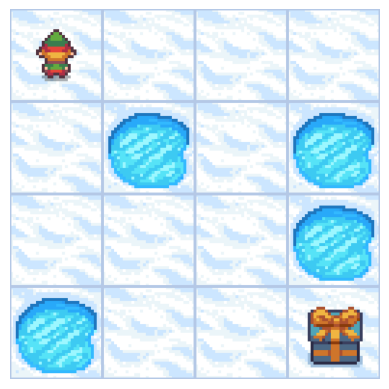

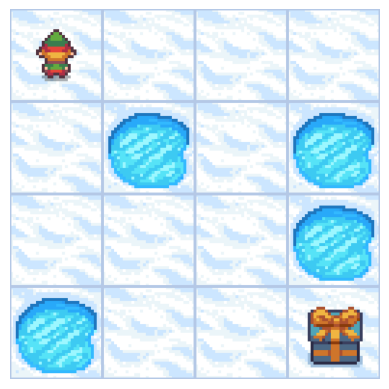

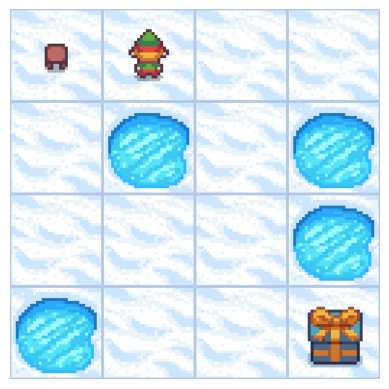

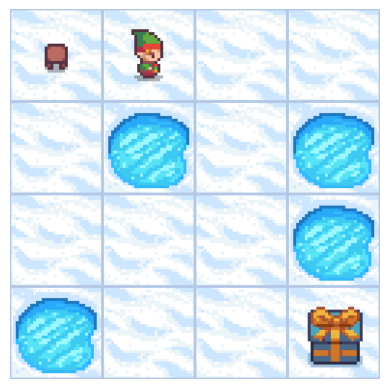

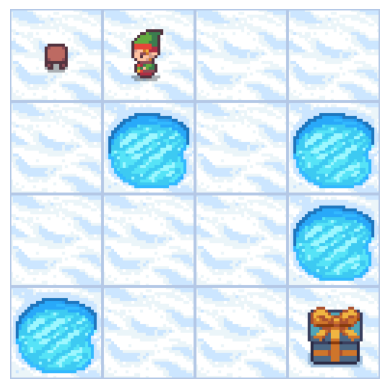

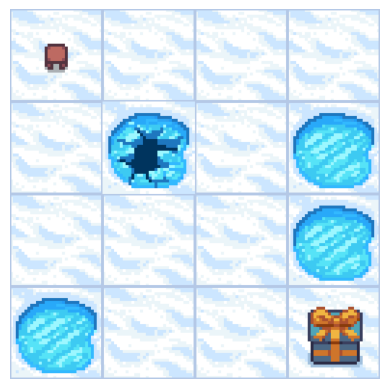

Final Q-table:
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


In [ ]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

# Create environment
env = gym.make("FrozenLake-v1", render_mode="rgb_array")

num_states = env.observation_space.n
num_actions = env.action_space.n

# Hyperparameters
alpha = 0.1     # learning rate
gamma = 0.8     # discount factor
num_episodes = 5

# Initialize Q-table
Q = np.zeros((num_states, num_actions))

# Render function
def render():
    frame = env.render()
    plt.imshow(frame)
    plt.axis("off")
    plt.show()

# SARSA Q-table update
def update_q_table(state, action, reward, next_state, next_action):
    old_value = Q[state, action]
    next_value = Q[next_state, next_action]

    Q[state, action] = (1 - alpha) * old_value + alpha * (reward + gamma * next_value)

# Training loop
for episode in range(num_episodes):
    state, info = env.reset()
    action = env.action_space.sample()
    terminated = False

    while not terminated:
        next_state, reward, terminated, truncated, info = env.step(action)
        next_action = env.action_space.sample()

        update_q_table(state, action, reward, next_state, next_action)

        render()

        state = next_state
        action = next_action

print("Final Q-table:")
print(Q)


**"FrozenLake-v1" with learning in each step (SARSA) with policy**

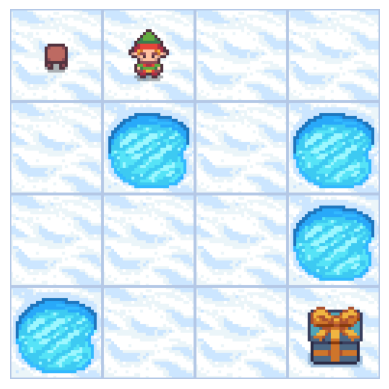

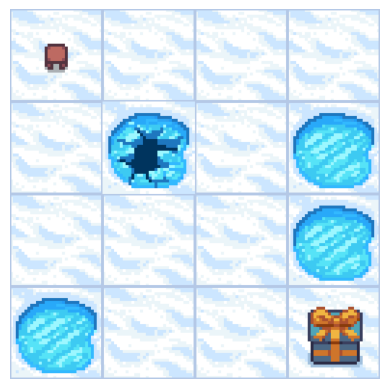

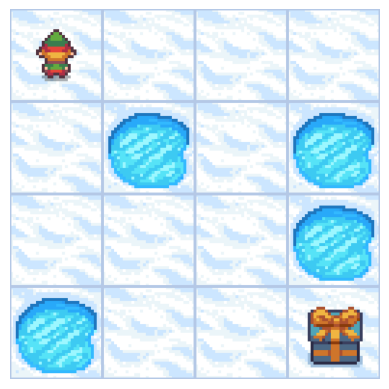

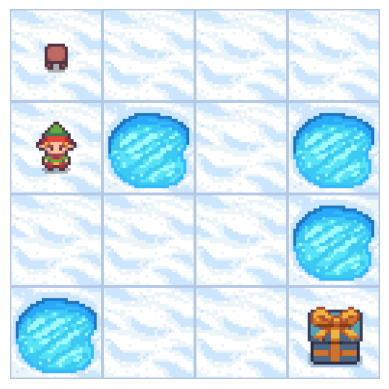

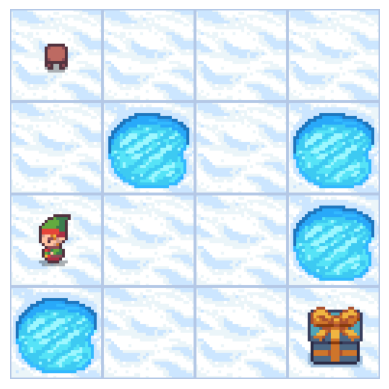

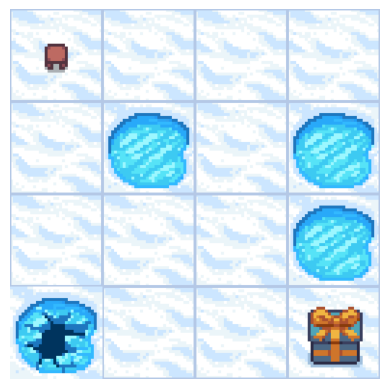

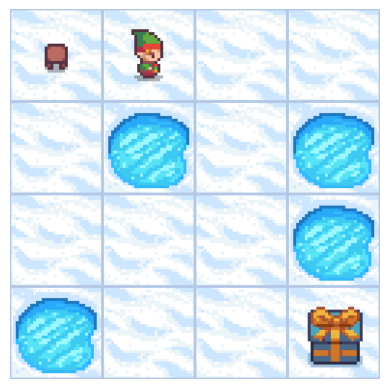

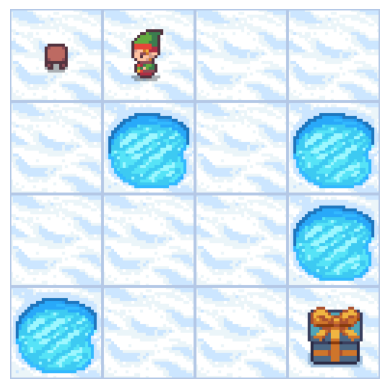

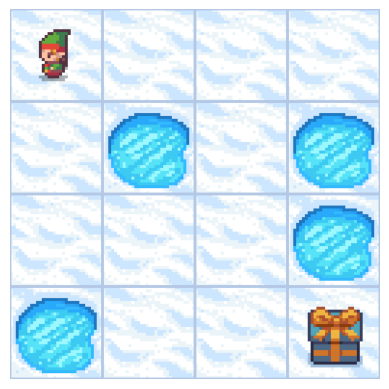

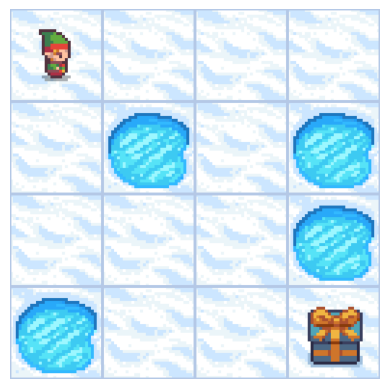

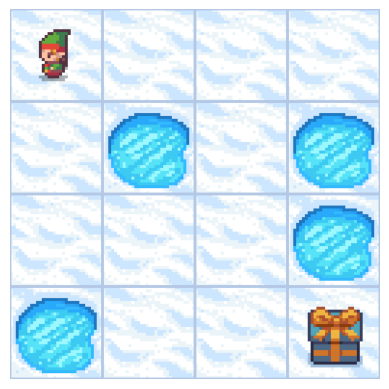

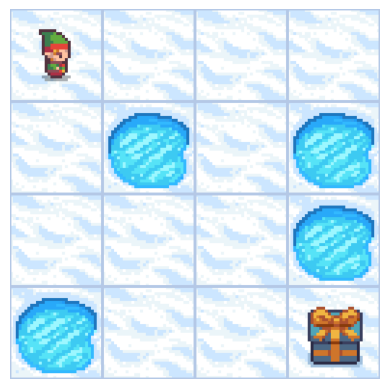

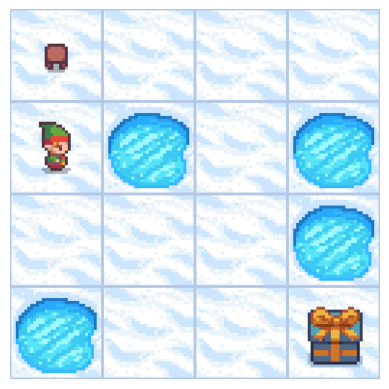

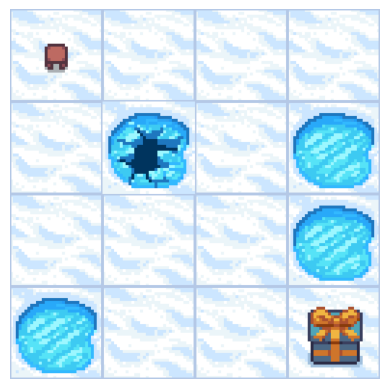

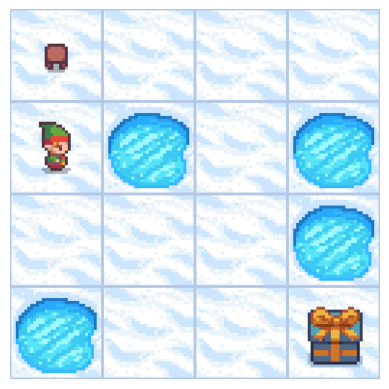

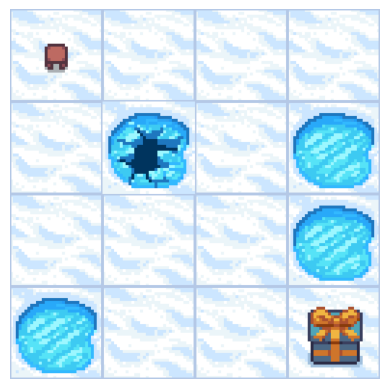

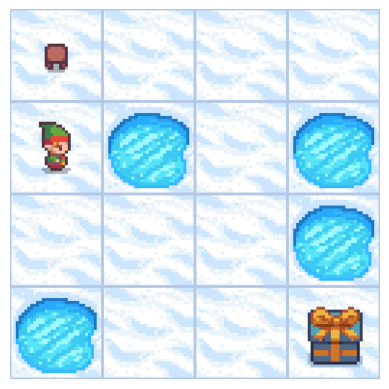

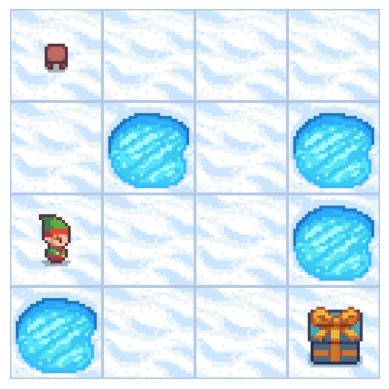

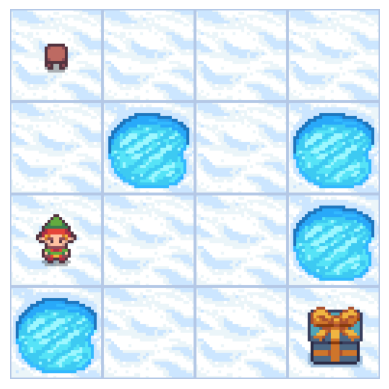

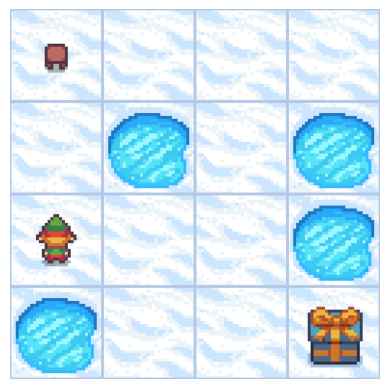

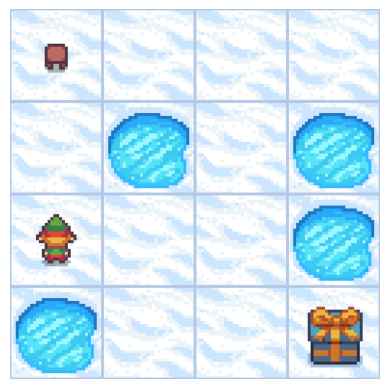

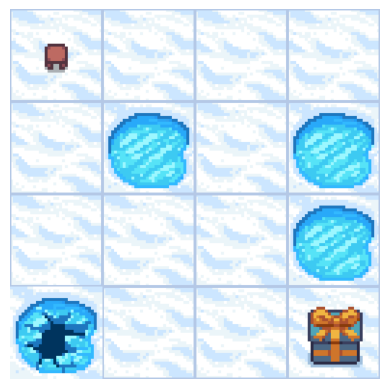

Learned Policy (best action per state):
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


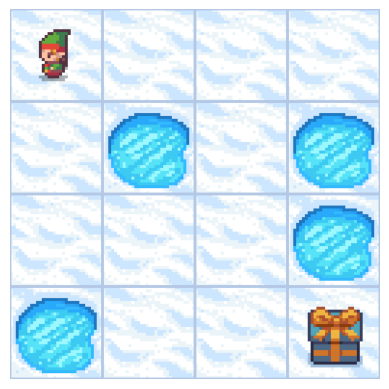

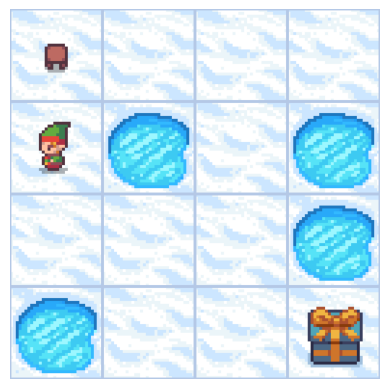

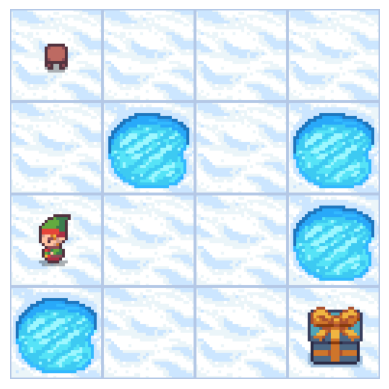

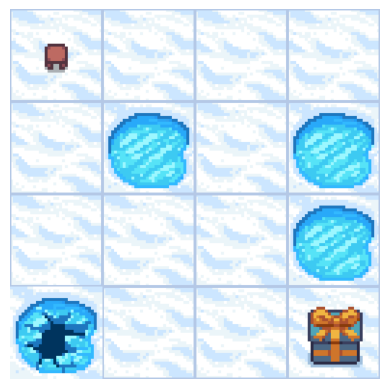

Total reward following learned policy: 0


In [ ]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

# Create environment
env = gym.make("FrozenLake-v1", render_mode="rgb_array")

num_states = env.observation_space.n
num_actions = env.action_space.n

# Hyperparameters
alpha = 0.1     # learning rate
gamma = 0.8     # discount factor
num_episodes = 5

# Initialize Q-table
Q = np.zeros((num_states, num_actions))

# Render function
def render():
    frame = env.render()
    plt.imshow(frame)
    plt.axis("off")
    plt.show()

# SARSA Q-table update
def update_q_table(state, action, reward, next_state, next_action):
    old_value = Q[state, action]
    next_value = Q[next_state, next_action]
    Q[state, action] = (1 - alpha) * old_value + alpha * (reward + gamma * next_value)

# Function to get the policy from the Q-table
def get_policy():
  #for the policy to work perfectly the agent should visit every state and perform every action in each state to provide the policy with all options to choose from
    policy = np.zeros(num_states, dtype=int)#make array of num_states which are filled with 0 initially
    for s in range(num_states):
        policy[s] = np.argmax(Q[s])  # pick action with highest Q-value
        '''example:
          state | left| right| up| down|
            0   |1    |2     |0.1|3    |
            here q value for down is highed=st so pick down
        '''
    return policy

# Training loop (SARSA with random actions)
for episode in range(num_episodes):
    state, info = env.reset()
    action = env.action_space.sample()  # initial random action
    terminated = False
    truncated = False

    while not (terminated or truncated):
        next_state, reward, terminated, truncated, info = env.step(action)
        next_action = env.action_space.sample()  # random next action for SARSA update

        update_q_table(state, action, reward, next_state, next_action)

        render()

        state = next_state
        action = next_action

# Derive the policy from the learned Q-table
policy = get_policy()
print("Learned Policy (best action per state):")
print(policy)

# Optional: test the policy
state, info = env.reset()
terminated = False
truncated = False
total_reward = 0

while not (terminated or truncated):
    action = policy[state]          # follow the best learned action
    state, reward, terminated, truncated, info = env.step(action)
    total_reward += reward
    render()

print("Total reward following learned policy:", total_reward)


**"FrozenLake-v1" with learning in each step (Q-learning) with policy**

In [ ]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

# Create environment
env = gym.make("FrozenLake-v1", render_mode="rgb_array")

num_states = env.observation_space.n
num_actions = env.action_space.n

# Hyperparameters
alpha = 0.1     # learning rate
gamma = 0.8     # discount factor
num_episodes = 5

# Initialize Q-table
Q = np.zeros((num_states, num_actions))

# Render function
def render():
    frame = env.render()
    plt.imshow(frame)
    plt.axis("off")
    plt.show()

# Q-learning update
def update_q_table(state, action, reward, next_state):
    old_value = Q[state, action]
    next_max = np.max(Q[next_state])  # maximum Q-value for next state
    Q[state, action] = (1 - alpha) * old_value + alpha * (reward + gamma * next_max)

# Function to get the policy from the Q-table
def get_policy():
    policy = np.zeros(num_states, dtype=int)
    for s in range(num_states):
        policy[s] = np.argmax(Q[s])  # best action per state
    return policy

# Training loop (Q-learning)
for episode in range(num_episodes):
    state, info = env.reset()
    terminated = False
    truncated = False

    while not (terminated or truncated):
        # Select a random action (pure exploration for now)
        action = env.action_space.sample()

        next_state, reward, terminated, truncated, info = env.step(action)

        # Q-learning update
        update_q_table(state, action, reward, next_state)

        render()

        state = next_state

# Derive the policy from the learned Q-table
policy = get_policy()
print("Learned Policy (best action per state):")
print(policy)

# Optional: test the policy
state, info = env.reset()
terminated = False
truncated = False
total_reward = 0

while not (terminated or truncated):
    action = policy[state]          # follow the best learned action
    state, reward, terminated, truncated, info = env.step(action)
    total_reward += reward
    render()

print("Total reward following learned policy:", total_reward)


# 'CliffWalking-v1'

In [ ]:
import gymnasium as gym

env = gym.make("CliffWalking-v1", render_mode="ansi")

def render():
    print(env.render()) #env.render()→returns a string because the full environment is text only so we can"t use the above one


def generate_episode():
    episode = []
    state, info = env.reset()
    terminated = False
    truncated = False

    while not (terminated or truncated):
        action = env.action_space.sample()
        next_state, reward, terminated, truncated, info = env.step(action)
        render()
        episode.append((state, action, reward))
        state = next_state

    return episode

print(generate_episode())


Streaming output truncated to the last 5000 lines.

o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
x  C  C  C  C  C  C  C  C  C  C  T


o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
x  C  C  C  C  C  C  C  C  C  C  T


o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
x  C  C  C  C  C  C  C  C  C  C  T


o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
x  C  C  C  C  C  C  C  C  C  C  T


o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
x  C  C  C  C  C  C  C  C  C  C  T


o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
x  C  C  C  C  C  C  C  C  C  C  T


o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o 

**Not completed yet(monte carlo)**

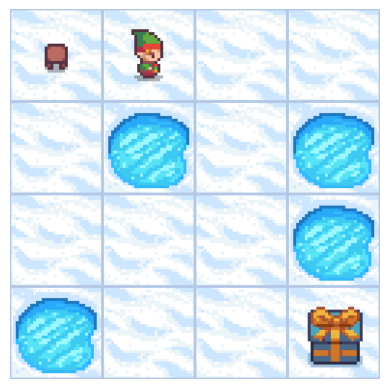

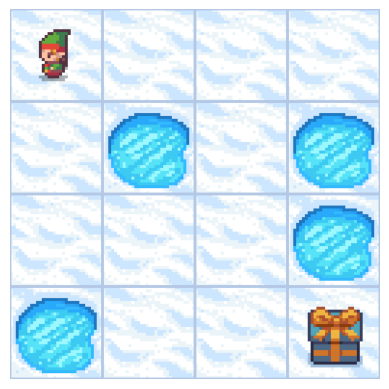

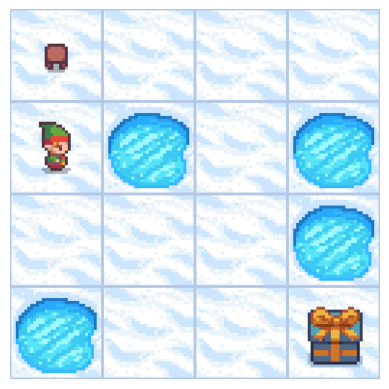

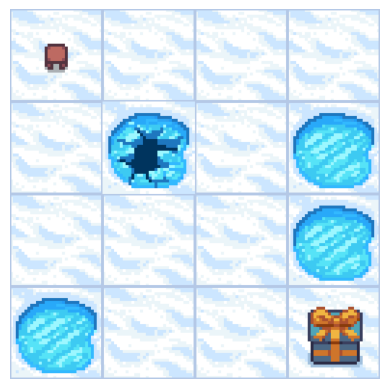

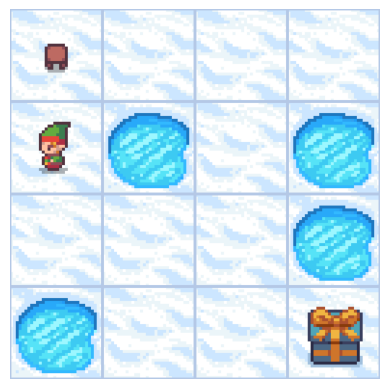

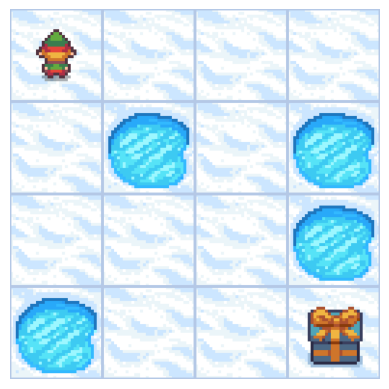

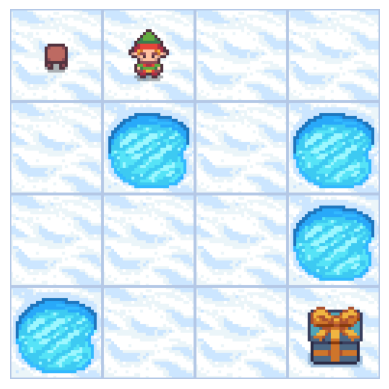

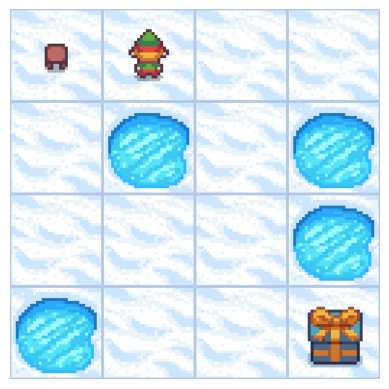

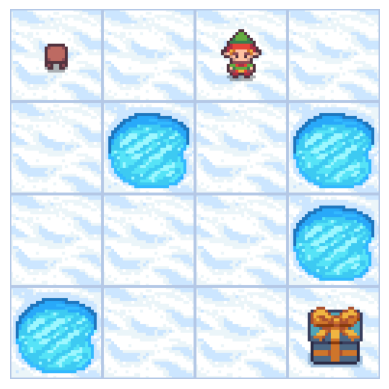

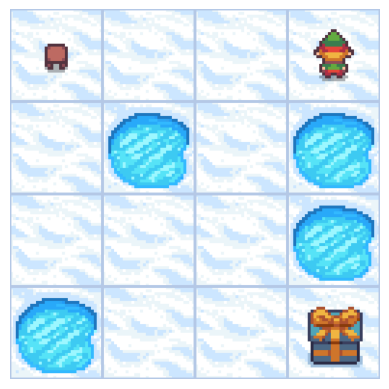

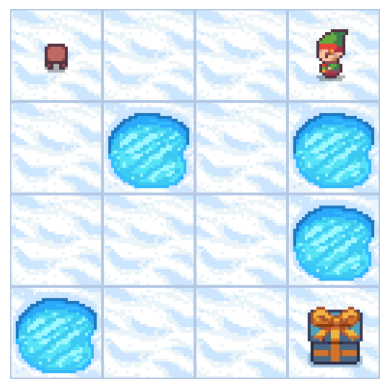

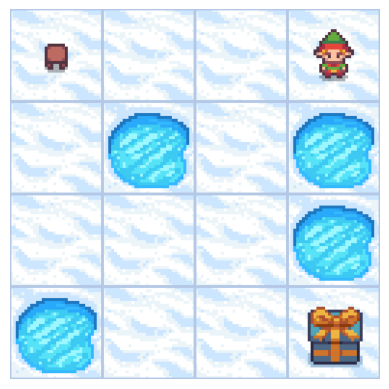

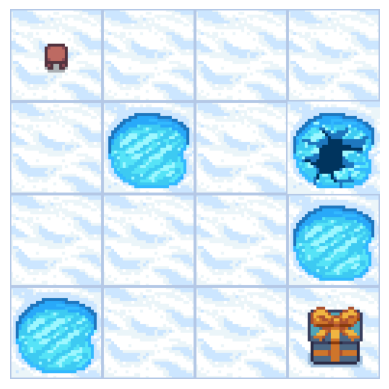

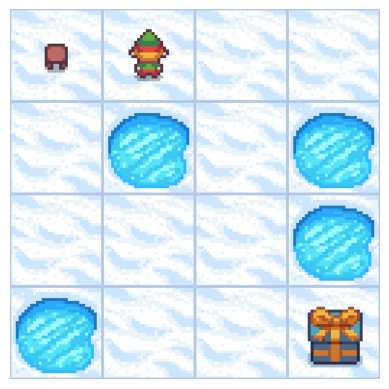

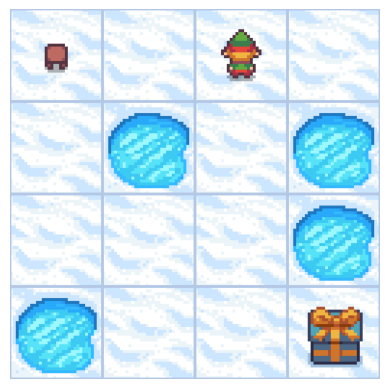

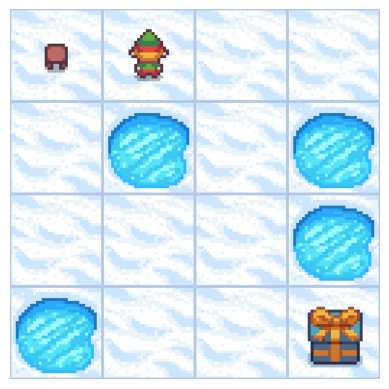

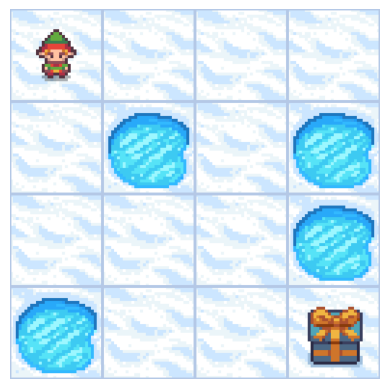

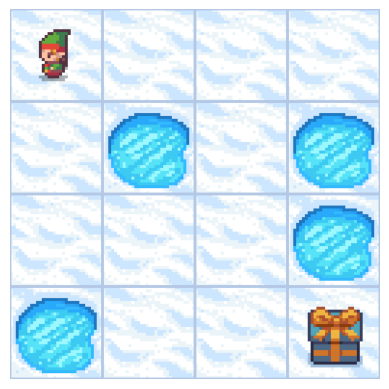

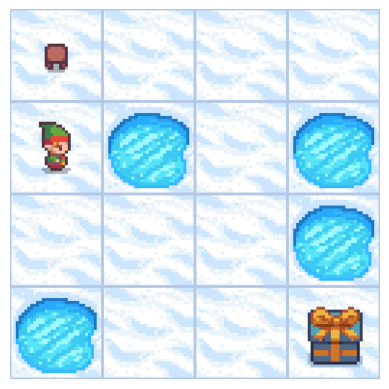

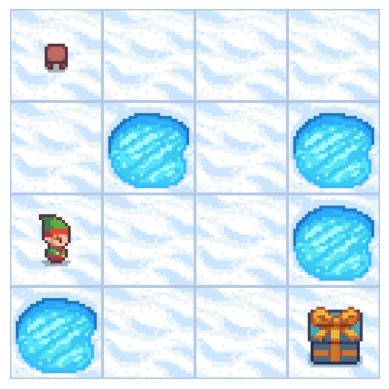

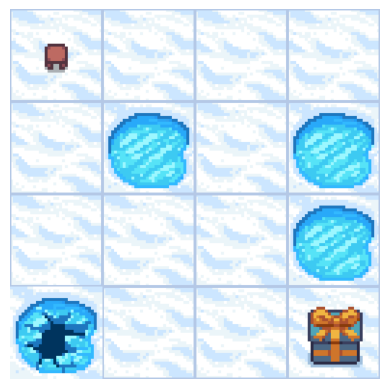

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


In [ ]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

# ---------------- ENVIRONMENT ----------------
env = gym.make("FrozenLake-v1", render_mode="rgb_array")

num_states = env.observation_space.n
num_actions = env.action_space.n

# ---------------- RENDER ----------------
def render():
    frame = env.render()
    plt.imshow(frame)
    plt.axis("off")
    plt.show()

# ---------------- EPISODE GENERATION ----------------
def generate_episode():
    episode = []
    state, info = env.reset()
    terminated = False

    while not terminated:
        action = env.action_space.sample()   # random action
        next_state, reward, terminated, truncated, info = env.step(action)

        render()
        episode.append((state, action, reward))
        state = next_state

    return episode

# ---------------- FIRST-VISIT MONTE CARLO ----------------
def first_visit_mc(num_episodes):
    Q = np.zeros((num_states, num_actions)) #np.zeros((num_states, num_actions))→generate num_state x num_action array all filled with 0
    #Q[state, action] = how good this action is in this state
    returns_sum = np.zeros((num_states, num_actions))  #np.zeros((num_states, num_actions))→generate num_state x num_action array all filled with 0
    #returns_sum→Total reward received for each (state, action)
    returns_count = np.zeros((num_states, num_actions)) #np.zeros((num_states, num_actions))→generate num_state x num_action array all filled with 0
    #returns_count→How many times each (state, action) was updated

    for i in range(num_episodes):
        episode = generate_episode()
        visited_state_actions = set() #create empty set named visited_state_actions

        for j, (state, action, reward) in enumerate(episode):
            if (state, action) not in visited_state_actions:
                G = sum([x[2] for x in episode[j:]])
                returns_sum[state, action] += G
                returns_count[state, action] += 1
                visited_state_actions.add((state, action)) #append (state, action) into visited_state_actions set


    for s in range(num_states): #This code computes the average reward for every (state, action) pair and stores it in the Q-table.
    for a in range(num_actions):
        if returns_count[s, a] != 0:
            Q[s, a] = returns_sum[s, a] / returns_count[s, a]


    return Q
Q = first_visit_mc(3)   # run 3 episodes only
print(Q)



**Not completed(taxi moving in video format)**

In [ ]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML

# ---------------- Environment ----------------
env = gym.make("Taxi-v3", render_mode="rgb_array")

num_states = env.observation_space.n
num_actions = env.action_space.n

# ---------------- Hyperparameters ----------------
alpha = 0.1
gamma = 0.99
epsilon = 0.1
num_episodes = 1000  # increase for better learning

# ---------------- Q-table ----------------
Q = np.zeros((num_states, num_actions))

# ---------------- Epsilon-greedy action ----------------
def choose_action(state):
    if np.random.rand() < epsilon:
        return env.action_space.sample()
    else:
        return np.argmax(Q[state])

# ---------------- SARSA update ----------------
def update_q_table(state, action, reward, next_state, next_action):
    Q[state, action] = (1 - alpha) * Q[state, action] + alpha * (reward + gamma * Q[next_state, next_action])

# ---------------- Training ----------------
for episode in range(num_episodes):
    state, info = env.reset()
    action = choose_action(state)
    terminated = False
    truncated = False

    while not (terminated or truncated):
        next_state, reward, terminated, truncated, info = env.step(action)
        next_action = choose_action(next_state)
        update_q_table(state, action, reward, next_state, next_action)
        state = next_state
        action = next_action

# ---------------- Derived policy ----------------
policy = np.array([np.argmax(Q[s]) for s in range(num_states)])
print("Learned policy (sample):", policy[:20], "...")  # just show first 20 states

# ---------------- Test episode (collect frames) ----------------
frames = []
state, info = env.reset()
terminated = False
truncated = False
total_reward = 0

while not (terminated or truncated):
    action = policy[state]  # follow learned policy
    state, reward, terminated, truncated, info = env.step(action)
    total_reward += reward
    frames.append(env.render())  # collect RGB frames

print("Total reward in test episode:", total_reward)
env.close()

# ---------------- Animation ----------------
fig = plt.figure(figsize=(6,6))
patch = plt.imshow(frames[0], interpolation='nearest')

def animate(i):
    patch.set_data(frames[i])

# Adjust interval to control speed
anim = animation.FuncAnimation(fig, animate, frames=len(frames), interval=200)
plt.close()
HTML(anim.to_jshtml())


Learned policy (sample): [0 4 4 4 2 0 2 1 0 2 0 2 2 2 1 0 5 0 0 2] ...
Total reward in test episode: 9
